<a id='intro'></a>
## Introduction

### Dataset Description 

The dataset "FBI GUN Data" and "U.S Census Data" represents the relationships 
between gun ownership in each state and the demographics of the states's populations.
The "FBI Gun Data" dataset has 27 columns; the columns show the different types of guns that were sold, rented, sold preivately, and returned back to the seller. This particular dataset has both categorical (e.g States) and numerical values (redemption_handgun, private_sale_handgun, etc.).

The data timeframe range from November of 1998 to septemper of 2017.
There are also alot of missing data that must be filled.
Data types are floats even Though they are all whole numbers.

The 'U.S Census Data" provides more indepth characteristics such as "the percentage of person under 18 years" for the state of Alabama. This Data also contains objects typed data, making it hard to graph.



### Question(s) for Analysis 

A questions that I am interested in exploring:

-Is there a relationship between education level and handgun?



In [1]:
import pandas as pd

df_gun= pd.read_csv('gun_data.csv')
df_gun.head()


,month,state,permit,permit_recheck,handgun,long_gun,other,multiple,admin,prepawn_handgun,...,returned_other,rentals_handgun,rentals_long_gun,private_sale_handgun,private_sale_long_gun,private_sale_other,return_to_seller_handgun,return_to_seller_long_gun,return_to_seller_other,totals
0,2017-09,Alabama,16717.0,0.0,5734.0,6320.0,221.0,317,0.0,15.0,...,0.0,0.0,0.0,9.0,16.0,3.0,0.0,0.0,3.0,32019
1,2017-09,Alaska,209.0,2.0,2320.0,2930.0,219.0,160,0.0,5.0,...,0.0,0.0,0.0,17.0,24.0,1.0,0.0,0.0,0.0,6303
2,2017-09,Arizona,5069.0,382.0,11063.0,7946.0,920.0,631,0.0,13.0,...,0.0,0.0,0.0,38.0,12.0,2.0,0.0,0.0,0.0,28394
3,2017-09,Arkansas,2935.0,632.0,4347.0,6063.0,165.0,366,51.0,12.0,...,0.0,0.0,0.0,13.0,23.0,0.0,0.0,2.0,1.0,17747
4,2017-09,California,57839.0,0.0,37165.0,24581.0,2984.0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,123506


In [2]:
df_gun.isna().sum()

month                            0
state                            0
permit                          24
permit_recheck               11385
handgun                         20
long_gun                        19
other                         6985
multiple                         0
admin                           23
prepawn_handgun               1943
prepawn_long_gun              1945
prepawn_other                 7370
redemption_handgun            1940
redemption_long_gun           1941
redemption_other              7370
returned_handgun             10285
returned_long_gun            10340
returned_other               10670
rentals_handgun              11495
rentals_long_gun             11660
private_sale_handgun          9735
private_sale_long_gun         9735
private_sale_other            9735
return_to_seller_handgun     10010
return_to_seller_long_gun     9735
return_to_seller_other       10230
totals                           0
dtype: int64

# Define function

In [3]:
def fill_in_NA(a):
    result = a.fillna(a.mean(numeric_only=True), inplace=True)
    return result

fill_in_NA(df_gun)


In [4]:
df_gun.isna().sum()

month                        0
state                        0
permit                       0
permit_recheck               0
handgun                      0
long_gun                     0
other                        0
multiple                     0
admin                        0
prepawn_handgun              0
prepawn_long_gun             0
prepawn_other                0
redemption_handgun           0
redemption_long_gun          0
redemption_other             0
returned_handgun             0
returned_long_gun            0
returned_other               0
rentals_handgun              0
rentals_long_gun             0
private_sale_handgun         0
private_sale_long_gun        0
private_sale_other           0
return_to_seller_handgun     0
return_to_seller_long_gun    0
return_to_seller_other       0
totals                       0
dtype: int64

# note

-double checking to make sure there are no more missing values.


In [5]:
df_gun['permit'] = df_gun['permit'].astype('int64')

float_cols = df_gun.select_dtypes(include='float64').columns

for col in float_cols:
    if (df_gun[col] % 1 == 0).all():
        df_gun[col] = df_gun[col].astype('Int64')

df_gun.info()

# observations
 
-I Attempted to convert all numeric values to integer due to all the numbers being whole numbers initially.
-However, filling in all the blanks with the mean made it not possible.


In [6]:
df_census= pd.read_csv('us_census_data.csv')
df_census.isna().sum()

Fact               5
Fact Note         57
Alabama           20
Alaska            20
Arizona           20
Arkansas          20
California        20
Colorado          20
Connecticut       20
Delaware          20
Florida           20
Georgia           20
Hawaii            20
Idaho             20
Illinois          20
Indiana           20
Iowa              20
Kansas            20
Kentucky          20
Louisiana         20
Maine             20
Maryland          20
Massachusetts     20
Michigan          20
Minnesota         20
Mississippi       20
Missouri          20
Montana           20
Nebraska          20
Nevada            20
New Hampshire     20
New Jersey        20
New Mexico        20
New York          20
North Carolina    20
North Dakota      20
Ohio              20
Oklahoma          20
Oregon            20
Pennsylvania      20
Rhode Island      20
South Carolina    20
South Dakota      20
Tennessee         20
Texas             20
Utah              20
Vermont           20
Virginia     

In [7]:
fill_in_NA(df_census)

#function reused

In [8]:
pd.set_option('display.max_rows', None)
df_census['Fact']


0          Population estimates, July 1, 2016,  (V2016)
1     Population estimates base, April 1, 2010,  (V2...
2     Population, percent change - April 1, 2010 (es...
3                     Population, Census, April 1, 2010
4     Persons under 5 years, percent, July 1, 2016, ...
5         Persons under 5 years, percent, April 1, 2010
6     Persons under 18 years, percent, July 1, 2016,...
7        Persons under 18 years, percent, April 1, 2010
8     Persons 65 years and over, percent,  July 1, 2...
9     Persons 65 years and over, percent, April 1, 2010
10     Female persons, percent,  July 1, 2016,  (V2016)
11               Female persons, percent, April 1, 2010
12         White alone, percent, July 1, 2016,  (V2016)
13    Black or African American alone, percent, July...
14    American Indian and Alaska Native alone, perce...
15         Asian alone, percent, July 1, 2016,  (V2016)
16    Native Hawaiian and Other Pacific Islander alo...
17    Two or More Races, percent, July 1, 2016, 

##Note
-Figuring out what information would be helpful in answering question #1

In [9]:
df_census_t = df_census.T   #Transpose
df_census_t.columns = df_census.iloc[:, 0]
df_census_t.index.name = 'state'
df_census_t = df_census_t.reset_index()
df_census_t= df_census_t.iloc[2:].reset_index(drop=True)
df_census_t.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 86 columns):
 #   Column                                                                                  Non-Null Count  Dtype 
---  ------                                                                                  --------------  ----- 
 0   state                                                                                   50 non-null     object
 1   Population estimates, July 1, 2016,  (V2016)                                            50 non-null     object
 2   Population estimates base, April 1, 2010,  (V2016)                                      50 non-null     object
 3   Population, percent change - April 1, 2010 (estimates base) to July 1, 2016,  (V2016)   50 non-null     object
 4   Population, Census, April 1, 2010                                                       50 non-null     object
 5   Persons under 5 years, percent, July 1, 2016,  (V2016)                          

## Observations

-unable to merge the 2 data set due to different formating.
-therefore, US_census was transposed.

In [10]:
df_gun.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12485 entries, 0 to 12484
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   month                      12485 non-null  object 
 1   state                      12485 non-null  object 
 2   permit                     12485 non-null  int64  
 3   permit_recheck             12485 non-null  float64
 4   handgun                    12485 non-null  float64
 5   long_gun                   12485 non-null  float64
 6   other                      12485 non-null  float64
 7   multiple                   12485 non-null  int64  
 8   admin                      12485 non-null  float64
 9   prepawn_handgun            12485 non-null  float64
 10  prepawn_long_gun           12485 non-null  float64
 11  prepawn_other              12485 non-null  float64
 12  redemption_handgun         12485 non-null  float64
 13  redemption_long_gun        12485 non-null  flo


### Research Question (Is there a relationship between education level and guns?)

In [11]:
df_merged = pd.merge(df_census_t, df_gun, on='state', how='outer')

In [12]:
df_merged.head()

,state,"Population estimates, July 1, 2016, (V2016)","Population estimates base, April 1, 2010, (V2016)","Population, percent change - April 1, 2010 (estimates base) to July 1, 2016, (V2016)","Population, Census, April 1, 2010","Persons under 5 years, percent, July 1, 2016, (V2016)","Persons under 5 years, percent, April 1, 2010","Persons under 18 years, percent, July 1, 2016, (V2016)","Persons under 18 years, percent, April 1, 2010","Persons 65 years and over, percent, July 1, 2016, (V2016)",...,returned_other,rentals_handgun,rentals_long_gun,private_sale_handgun,private_sale_long_gun,private_sale_other,return_to_seller_handgun,return_to_seller_long_gun,return_to_seller_other,totals
0,Alabama,"4,863,300","4,780,131",1.70%,"4,779,736",6.00%,6.40%,22.60%,23.70%,16.10%,...,0.0,0.0,0.0,9.0,16.0,3.0,0.0,0.0,3.0,32019
1,Alabama,"4,863,300","4,780,131",1.70%,"4,779,736",6.00%,6.40%,22.60%,23.70%,16.10%,...,0.0,0.0,0.0,14.0,11.0,2.0,0.0,0.0,0.0,35038
2,Alabama,"4,863,300","4,780,131",1.70%,"4,779,736",6.00%,6.40%,22.60%,23.70%,16.10%,...,0.0,0.0,0.0,12.0,8.0,0.0,0.0,0.0,0.0,31474
3,Alabama,"4,863,300","4,780,131",1.70%,"4,779,736",6.00%,6.40%,22.60%,23.70%,16.10%,...,0.0,0.0,0.0,16.0,9.0,0.0,1.0,1.0,1.0,35687
4,Alabama,"4,863,300","4,780,131",1.70%,"4,779,736",6.00%,6.40%,22.60%,23.70%,16.10%,...,0.0,0.0,0.0,12.0,11.0,1.0,0.0,1.0,1.0,33331


## note
-Because the 'Bachelor's degree or higher, percent of persons age 25 years+, 2011-2015' column is only from 2011-2015. We must filter out df_gun to only 2011-1025


In [13]:
df_gun['month'] = pd.to_datetime(df_gun['month'])
df_gun['year'] = df_gun['month'].dt.year

df_gun_filtered = df_gun[
    df_gun['year'].between(2011, 2015)
]

 ## Observations

-These are the average total of hand gun sold by year.

In [14]:
pd.set_option('display.max_rows', None)
df_merged_n = pd.merge(df_census_t, df_gun_filtered, on='state', how='outer')
df_merged_n

,state,"Population estimates, July 1, 2016, (V2016)","Population estimates base, April 1, 2010, (V2016)","Population, percent change - April 1, 2010 (estimates base) to July 1, 2016, (V2016)","Population, Census, April 1, 2010","Persons under 5 years, percent, July 1, 2016, (V2016)","Persons under 5 years, percent, April 1, 2010","Persons under 18 years, percent, July 1, 2016, (V2016)","Persons under 18 years, percent, April 1, 2010","Persons 65 years and over, percent, July 1, 2016, (V2016)",...,rentals_handgun,rentals_long_gun,private_sale_handgun,private_sale_long_gun,private_sale_other,return_to_seller_handgun,return_to_seller_long_gun,return_to_seller_other,totals,year
0,Alabama,"4,863,300","4,780,131",1.70%,"4,779,736",6.00%,6.40%,22.60%,23.70%,16.10%,...,0.076768,0.087273,12.000,14.000000,4.000000,2.00000,0.000000,0.000000,120914,2015
1,Alabama,"4,863,300","4,780,131",1.70%,"4,779,736",6.00%,6.40%,22.60%,23.70%,16.10%,...,0.076768,0.087273,13.000,14.000000,0.000000,3.00000,2.000000,0.000000,71137,2015
2,Alabama,"4,863,300","4,780,131",1.70%,"4,779,736",6.00%,6.40%,22.60%,23.70%,16.10%,...,0.076768,0.087273,9.000,11.000000,2.000000,2.00000,2.000000,0.000000,61156,2015
3,Alabama,"4,863,300","4,780,131",1.70%,"4,779,736",6.00%,6.40%,22.60%,23.70%,16.10%,...,0.076768,0.087273,4.000,9.000000,0.000000,2.00000,1.000000,0.000000,56228,2015
4,Alabama,"4,863,300","4,780,131",1.70%,"4,779,736",6.00%,6.40%,22.60%,23.70%,16.10%,...,0.076768,0.087273,0.000,0.000000,0.000000,0.00000,0.000000,0.000000,62770,2015
5,Alabama,"4,863,300","4,780,131",1.70%,"4,779,736",6.00%,6.40%,22.60%,23.70%,16.10%,...,0.076768,0.087273,0.000,0.000000,0.000000,0.00000,0.000000,0.000000,56762,2015
6,Alabama,"4,863,300","4,780,131",1.70%,"4,779,736",6.00%,6.40%,22.60%,23.70%,16.10%,...,0.076768,0.087273,0.000,0.000000,0.000000,0.00000,0.000000,0.000000,45952,2015
7,Alabama,"4,863,300","4,780,131",1.70%,"4,779,736",6.00%,6.40%,22.60%,23.70%,16.10%,...,0.076768,0.087273,0.000,0.000000,0.000000,0.00000,0.000000,0.000000,45128,2015
8,Alabama,"4,863,300","4,780,131",1.70%,"4,779,736",6.00%,6.40%,22.60%,23.70%,16.10%,...,0.076768,0.087273,0.000,0.000000,0.000000,0.00000,0.000000,0.105987,46971,2015
9,Alabama,"4,863,300","4,780,131",1.70%,"4,779,736",6.00%,6.40%,22.60%,23.70%,16.10%,...,0.076768,0.087273,0.000,0.000000,0.000000,0.00000,0.000000,0.105987,57152,2015


In [15]:
df_merged_avg = df_merged_n.groupby('year')['handgun'].mean()
df_merged_avg

year
2011     6517.256061
2012     8610.550000
2013     9678.033333
2014     9392.792424
2015    11111.830303
Name: handgun, dtype: float64

In [16]:
col = "Bachelor's degree or higher, percent of persons age 25 years+, 2011-2015"

df_merged_n[col] = pd.to_numeric(
    df_merged_n[col].astype(str).str.replace('%', '', regex=False),
    errors='coerce'
)

df_merged_n[col].dtype

dtype('float64')

<AxesSubplot: title={'center': 'Relationship Between Handgun Ownership and Education Level'}, xlabel="Bachelor's degree or higher, percent of persons age 25 years+, 2011-2015", ylabel='handgun'>

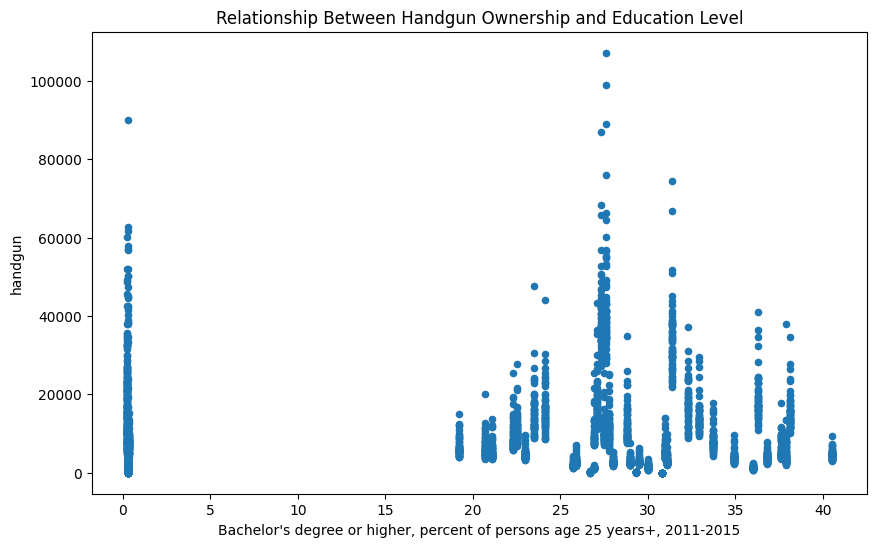

In [17]:
col = "Bachelor's degree or higher, percent of persons age 25 years+, 2011-2015"

df_merged_n.plot(
kind='scatter',
x=col,
y='handgun',
title = "Relationship Between Handgun Ownership and Education Level",
figsize=(10, 6))

In [18]:
import numpy as np

x= df_merged_n[col]
y =df_merged_n['handgun']

df_merged_n[['handgun', col]].isna().sum()

handgun                                                                       0
Bachelor's degree or higher, percent of persons age 25 years+, 2011-2015    300
dtype: int64

In [19]:
df_clean = df_merged_n.dropna(subset=['handgun', col])

In [20]:
df_clean['handgun'].corr(df_clean[col])

0.0038388977541250705

# Correlations
-little to no relationship

In [21]:
df_merged_n[['permit', col]].isna().sum()

permit                                                                        0
Bachelor's degree or higher, percent of persons age 25 years+, 2011-2015    300
dtype: int64

In [22]:
df_state_avg = df_merged_n.groupby('state').mean(numeric_only=True).reset_index()
df_state_avg = df_state_avg.sort_values(by=col)

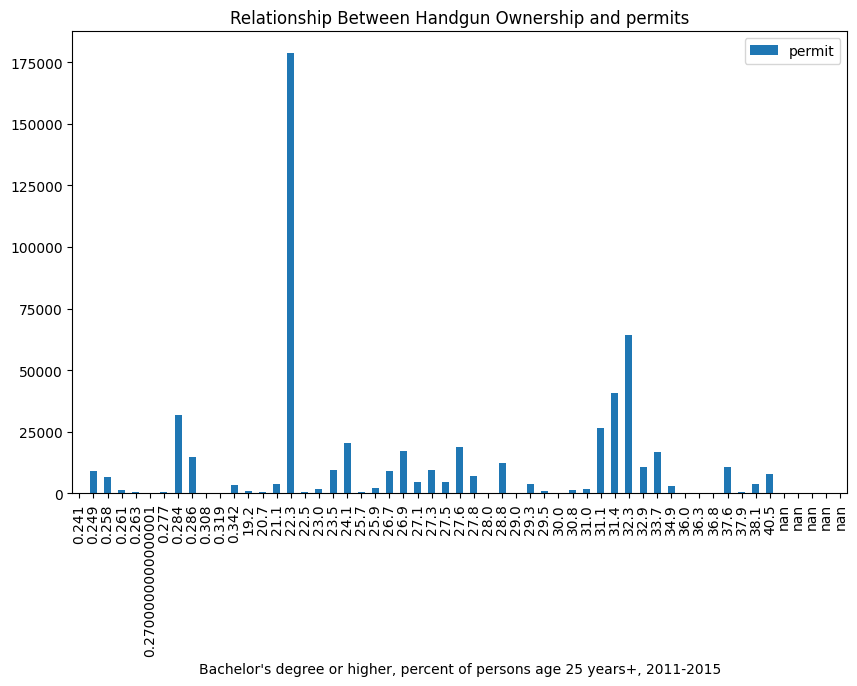

In [23]:
df_state_avg.plot(
kind='bar',
x=col,
y='permit',
title = "Relationship Between Handgun Ownership and permits",
figsize=(10, 6))

df_state_avg[col] = df_state_avg[col].round(2)

# Correlations

In [24]:
df_clean['permit'].corr(df_clean[col])

0.04644951974175998

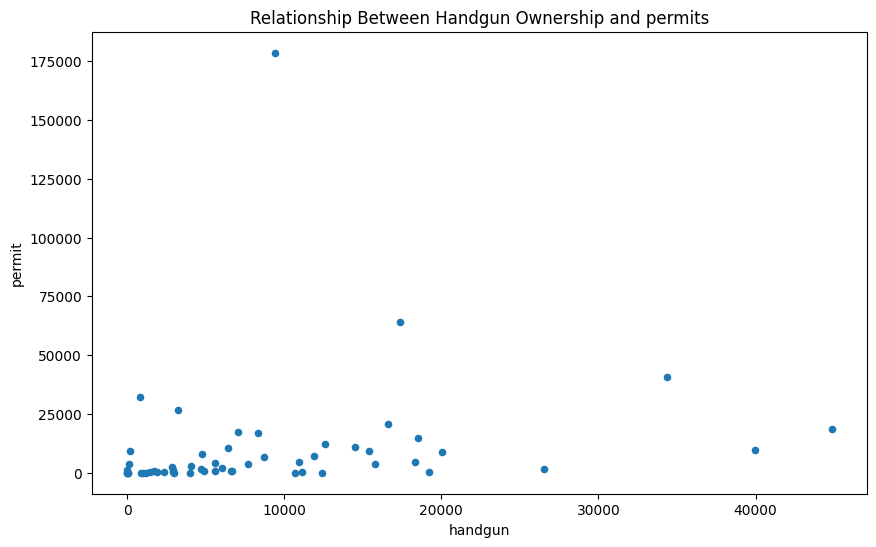

In [25]:
df_state_avg.plot(
kind='scatter',
x='handgun',
y='permit',
title = "Relationship Between Handgun Ownership and permits",
figsize=(10, 6))

df_state_avg[col] = df_state_avg[col].round(2)

In [26]:
df_clean['permit'].corr(df_clean['handgun'])

0.1507600447162847

In [27]:
df_state_avg[['handgun', 'permit', col]].describe()


,handgun,permit,"Bachelor's degree or higher, percent of persons age 25 years+, 2011-2015"
count,55.000000,55.000000,50.000000
mean,9062.092424,10288.103636,22.363200
std,9855.907158,25886.161837,13.383629
min,0.000000,0.000000,0.240000
25%,2113.775000,150.550000,19.575000
50%,6064.033333,2404.600000,27.200000
75%,12520.141667,9460.333333,31.075000
max,44841.416667,178562.016667,40.500000


## Final Observations

-According to the first visualization, States where 25% to 30% of the population attains a Bachelor's degree or higher reports the highest number of handgun ownership.

-The correlation of 0.0038 suggests little to no relationship between the percentage of individuals with higher education and handgun ownership at the state level.

-While the majority of values are concentrated at higher levels, there is also a noticeable cluster of low values near zero, indicating that states with extremly low percentage of individuals with higher education still has alot of handgun owners.

-For the second graph, I am exploring more into the relationship of permit holders and the percentage of individuals with higher education per state. The correlation of 0.046 shows a stronger relationship between these two variables compared to the frist graph. The data is more skewed left; it shows that majority of permit holders are from states with higher percentage of bachelors or higher degree holders.

-For the third graph, it shows the relationship between handgun owners and permit holders. The average handgun owner through all 50 states is around 9,062, whereas the average permit holders is 10,288. This shows that on average we have more permit holders than handgun owners in the country
-However, the graph shows that majority of the states actually has more handgun owners compared to permit holders, with a couple extreme outliers.

#Limitation
-The original goal was to examine how an individual’s level of education relates to handgun ownership. However, the available data is aggregated at the state level, showing the percentage of individuals with higher education rather than individual behavior. As a result, the analysis reflects differences between states rather than how education influences handgun ownership at the individual level. Therefore, conclusions about individual behavior cannot be definitively drawn.

In [28]:
!python -m nbconvert --to html Investigate_a_Dataset.ipynb

[NbConvertApp] Converting notebook Investigate_a_Dataset.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 3 image(s).
[NbConvertApp] Writing 1736103 bytes to Investigate_a_Dataset.html
